# Mice Protein Expression: Decision Tree Classification

**Objective:** Predict the experimental class (genotype × treatment × behaviour) from the 77 protein expression levels, and see which proteins drive the decisions.

Data loading and splitting come from `scripts/data_pipeline.py`, so we use the same 70/15/15 splits as KNN and the other models (`SEED = 42`).

In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from data_pipeline import get_train_val_test_split, SEED, MODELS_DIR, FIGURES_DIR

sns.set_theme(style='whitegrid', font_scale=1.1)

In [4]:
np.random.seed(SEED)

X_train, X_val, X_test, y_train, y_val, y_test = get_train_val_test_split()
labels = sorted(y_train.unique())

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Features: {X_train.shape[1]} proteins | Classes: {len(labels)}")

Train: 756 | Val: 162 | Test: 162
Features: 77 proteins | Classes: 8


## 1. Tuning `max_depth`

Shallow trees underfit, deep trees memorise noise. We sweep depths 2-15 and pick the best on the validation set using accuracy. Imputation sits inside the pipeline so it's fitted on the training fold only, no scaling needed for trees. The test set stays untouched until the end.

Optimal Tree Depth: 9 (Validation Accuracy: 85.80%)


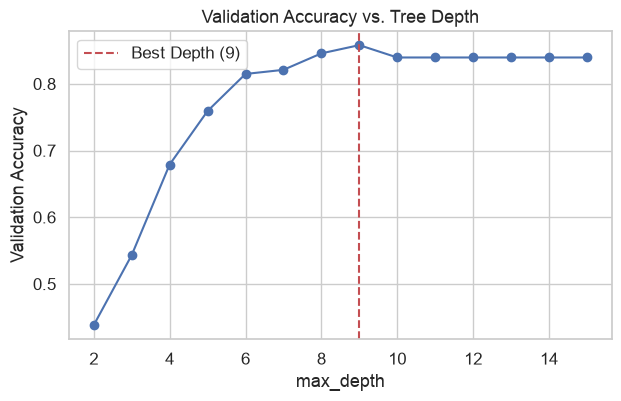

In [5]:
depths = range(2, 16)
val_accuracies = []

for depth in depths:
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])
    pipeline.fit(X_train, y_train)
    val_pred = pipeline.predict(X_val)
    val_accuracies.append(accuracy_score(y_val, val_pred))

best_depth = depths[np.argmax(val_accuracies)]
print(f"Optimal Tree Depth: {best_depth} (Validation Accuracy: {max(val_accuracies):.2%})")

# Plot tuning curve
plt.figure(figsize=(7, 4))
plt.plot(depths, val_accuracies, marker='o')
plt.title('Validation Accuracy vs. Tree Depth')
plt.xlabel('max_depth')
plt.ylabel('Validation Accuracy')
plt.axvline(best_depth, color='r', linestyle='--', label=f'Best Depth ({best_depth})')
plt.legend()
plt.show()

## 2. Final fit & test evaluation

Refit at the best depth and evaluate on the untouched test set, then save the pipeline for the R3 comparison.

In [ ]:
dt_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)),
])
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, labels=labels, digits=3))

Test accuracy: 0.8025
Test macro F1: 0.7989

              precision    recall  f1-score   support

      c-CS-m      0.714     0.652     0.682        23
      c-CS-s      0.737     0.700     0.718        20
      c-SC-m      0.875     0.955     0.913        22
      c-SC-s      0.818     0.900     0.857        20
      t-CS-m      0.842     0.762     0.800        21
      t-CS-s      0.667     0.750     0.706        16
      t-SC-m      0.864     0.950     0.905        20
      t-SC-s      0.882     0.750     0.811        20

    accuracy                          0.802       162
   macro avg      0.800     0.802     0.799       162
weighted avg      0.803     0.802     0.800       162

Saved best decision tree model to /Users/nirup/git/F21DL-2026-27-UG-group-17/models/decision_tree_best_model.joblib


## 3. Feature importance & error patterns

Which proteins actually drive the splits, and where does the model get confused?

/var/folders/mt/5cqwsp8j2rz5nl7llvnrr_9r0000gn/T/ipykernel_80994/1918914203.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_proteins.values, y=top10_proteins.index, ax=ax[0], palette='viridis')


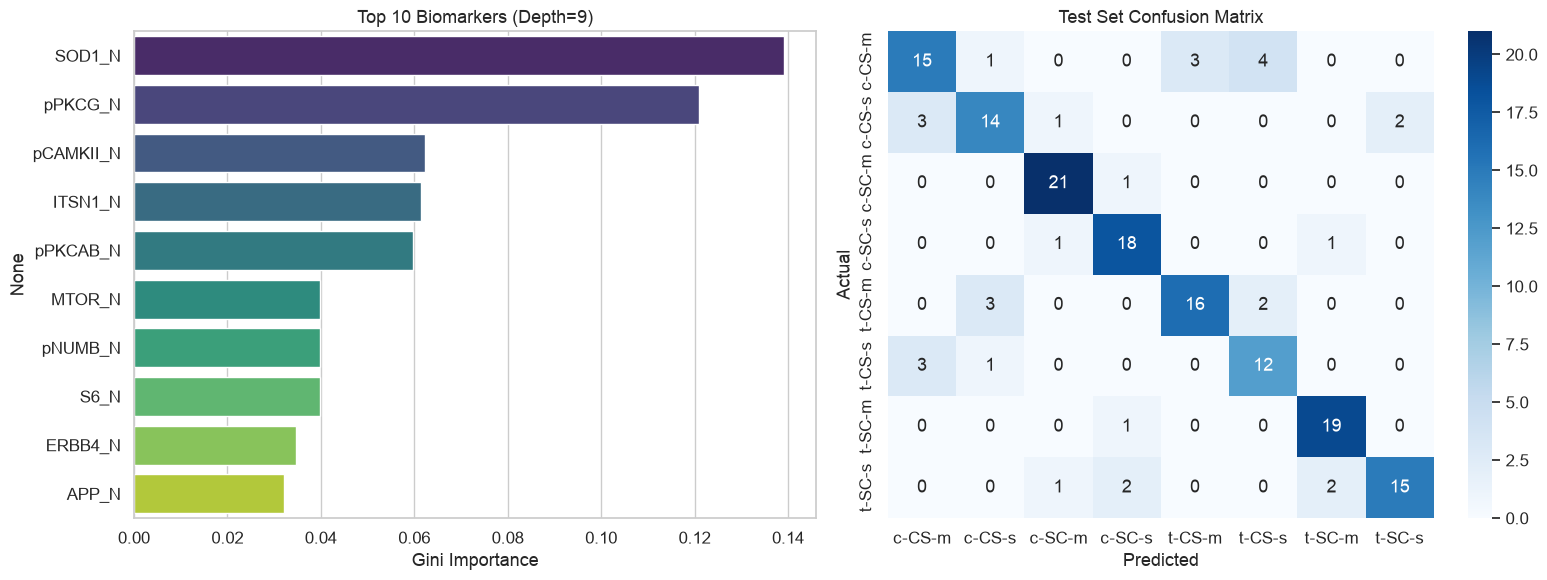

In [ ]:
# Feature importances
importances = pd.Series(dt_model.named_steps['tree'].feature_importances_, index=X_train.columns)
top10_proteins = importances.sort_values(ascending=False).head(10)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Plot top proteins
sns.barplot(x=top10_proteins.values, y=top10_proteins.index, ax=ax[0], palette='viridis')
ax[0].set_title(f'Top 10 Biomarkers (Depth={best_depth})')
ax[0].set_xlabel('Gini Importance')

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[1],
            xticklabels=labels, 
            yticklabels=labels)
ax[1].set_title('Test Set Confusion Matrix')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 4. Discussion

Accuracy (0.80) and macro F1 (0.80) land almost on top of each other, so the tree isn't sacrificing one class to prop up another - performance is fairly even across all eight despite the slightly uneven class sizes.

The errors split on **behaviour**, not genotype. All four SC classes sit at F1 0.81-0.91, while the CS classes trail at 0.68-0.80 (avg 0.87 vs 0.73). Genotype barely matters - control averaged 0.79 vs trisomy 0.81 - and treatment is a weaker effect again (memantine 0.83 vs saline 0.77). That lines up with `clustering.ipynb`, where behaviour drove the largest variance and the saline/memantine axis was too subtle for K-Means to separate. The two weak spots are `c-CS-m` (recall 0.65 - roughly a third of them get missed) and `t-CS-s` (precision 0.67 - it absorbs other classes' mistakes).

The top-ranked proteins are candidate biomarkers for the experimental conditions, and unlike a black-box model we can read the decision path directly - that interpretability is the practical appeal of trees in this kind of biomedical setting. (Gini importance is computed on training data though, so treat the ranking as a hypothesis, not a validated finding.)